# Приоритизация обзвона клиентов банка

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from joblib import parallel_backend
from scipy.stats import hypergeom, spearmanr
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    make_scorer,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedGroupKFold,
    cross_val_predict,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

In [2]:
RANDOM_STATE = 42
CALL_COST = 5.0
DEPOSIT_MARGIN = 50.0


plt.style.use('default')
plt.rcParams.update({
    'font.size': 10,
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titleweight': 'bold',
})

## 1. Данные и разведочный анализ

In [3]:
data = pd.read_csv('bank-additional-full.csv', sep=';')
features = data.drop(columns=['duration', 'campaign', 'y'])
target = data['y'].eq('yes').astype(int)

groups = pd.util.hash_pandas_object(features, index=False).to_numpy()
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)
train_indices, test_indices = next(splitter.split(features, target, groups))

X_train = features.iloc[train_indices].copy()
X_test = features.iloc[test_indices].copy()
y_train = target.iloc[train_indices].copy()
y_test = target.iloc[test_indices].copy()
train_groups = groups[train_indices]
test_groups = groups[test_indices]

eda = data.iloc[train_indices].copy()
eda['target'] = y_train.to_numpy()

In [4]:
data_quality = pd.Series({
    'Наблюдения': len(data),
    'Столбцы': data.shape[1],
    'Согласия': target.sum(),
    'Доля согласий': target.mean(),
    'Пустые ячейки': data.isna().sum().sum(),
    'Полные дубликаты': data.duplicated().sum(),
    'Повторяющиеся входные профили сверх первого': features.duplicated().sum(),
    'Записи с pdays = 999': data['pdays'].eq(999).sum(),
    'Совпадения групп train и test': len(set(train_groups) & set(test_groups)),
}, name='Значение')

split_summary = pd.DataFrame({
    'Наблюдения': [len(X_train), len(X_test)],
    'Согласия': [y_train.sum(), y_test.sum()],
    'Доля согласий': [y_train.mean(), y_test.mean()],
}, index=['train', 'test'])

unknown_counts = data.eq('unknown').sum()
unknown_counts = unknown_counts[unknown_counts > 0].sort_values(ascending=False)


display(data_quality.to_frame())
display(data.dtypes.astype(str).rename('Тип').to_frame())
display(unknown_counts.rename('Число unknown').to_frame())
display(data.describe())
display(split_summary)

,Значение
Наблюдения,41188.000000
Столбцы,21.000000
Согласия,4640.000000
Доля согласий,0.112654
Пустые ячейки,0.000000
Полные дубликаты,12.000000
Повторяющиеся входные профили сверх первого,4585.000000
Записи с pdays = 999,39673.000000
Совпадения групп train и test,0.000000


,Тип
age,int64
job,object
marital,object
education,object
default,object
housing,object
loan,object
contact,object
month,object
day_of_week,object


,Число unknown
default,8597
education,1731
housing,990
loan,990
job,330
marital,80


,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


,Наблюдения,Согласия,Доля согласий
train,32929,3712,0.112727
test,8259,928,0.112362


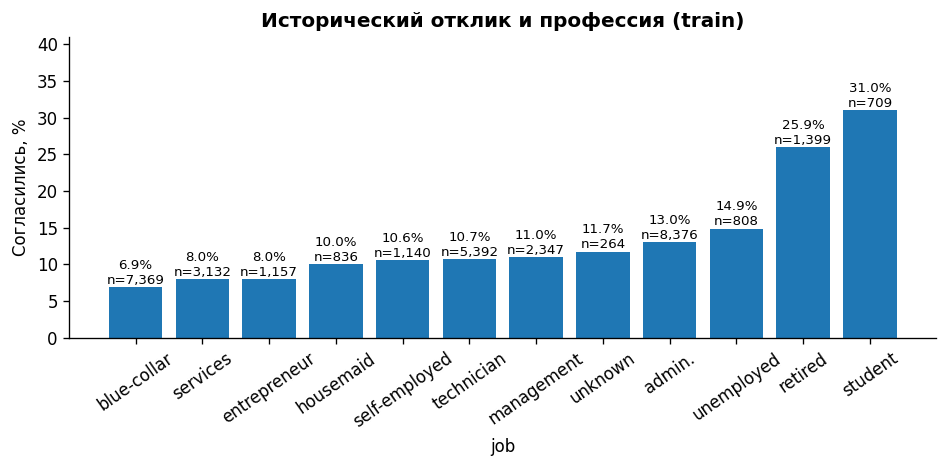

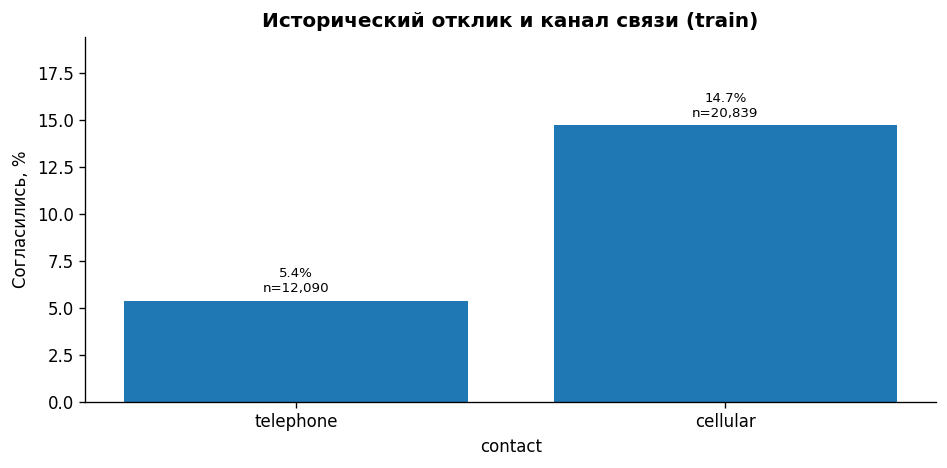

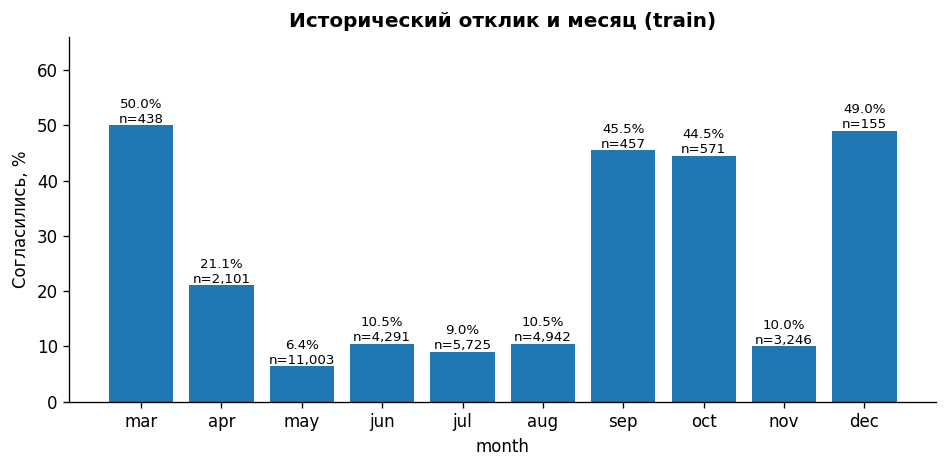

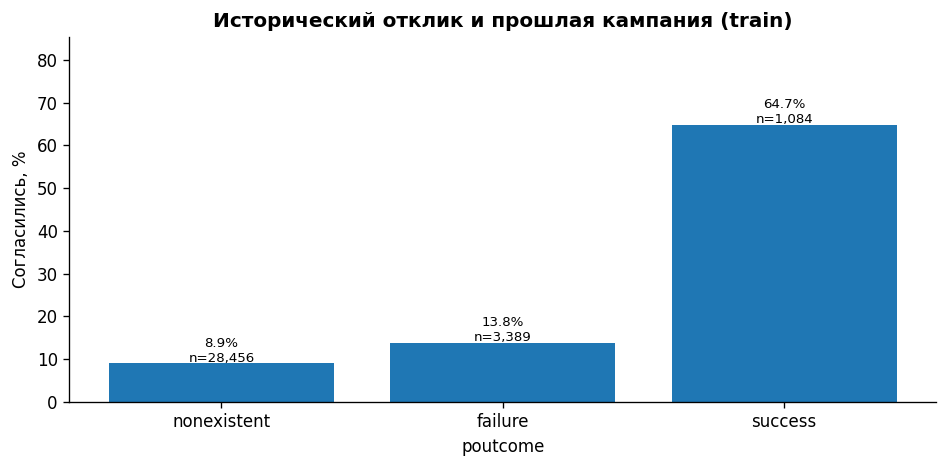

In [5]:
def response_by_group(frame, feature):
    return frame.groupby(feature, observed=True)['target'].agg(
        n='size',
        yes='sum',
        response_rate='mean',
    )


def plot_response(table, title, xlabel, rotation=0):
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(table.index, table['response_rate'] * 100)
    for position, (count, rate) in enumerate(zip(table['n'], table['response_rate'])):
        ax.text(
            position,
            rate * 100 + 0.45,
            f'{rate:.1%}\nn={count:,}',
            ha='center',
            fontsize=8,
        )
    ax.set(
        xlabel=xlabel,
        ylabel='Согласились, %',
        title=title,
        ylim=(0, table['response_rate'].max() * 100 * 1.32),
    )
    ax.tick_params(axis='x', rotation=rotation)
    plt.tight_layout()
    plt.show()


month_order = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
feature_titles = {
    'job': 'профессия',
    'contact': 'канал связи',
    'month': 'месяц',
    'poutcome': 'прошлая кампания',
}
eda_tables = {}

for feature, title in feature_titles.items():
    table = response_by_group(eda, feature)
    if feature == 'month':
        table = table.reindex([month for month in month_order if month in table.index])
    else:
        table = table.sort_values('response_rate')

    eda_tables[feature] = table
    plot_response(
        table,
        f'Исторический отклик и {title} (train)',
        xlabel=feature,
        rotation=35 if feature == 'job' else 0,
    )

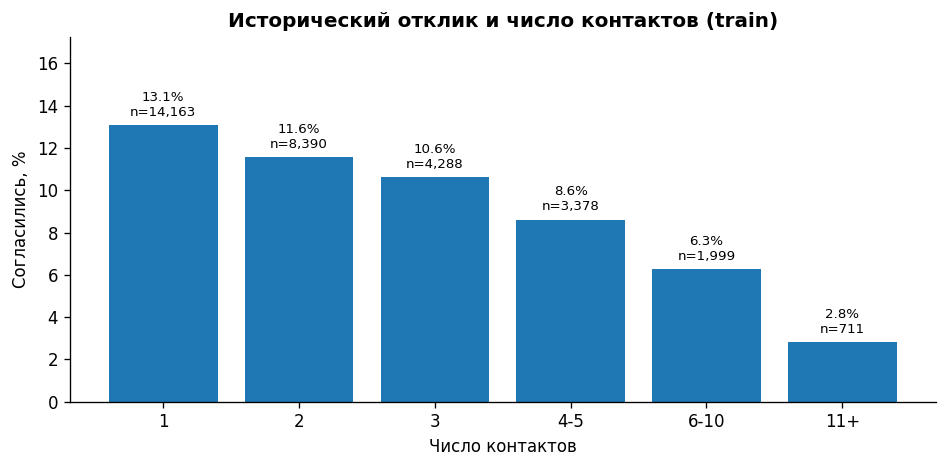

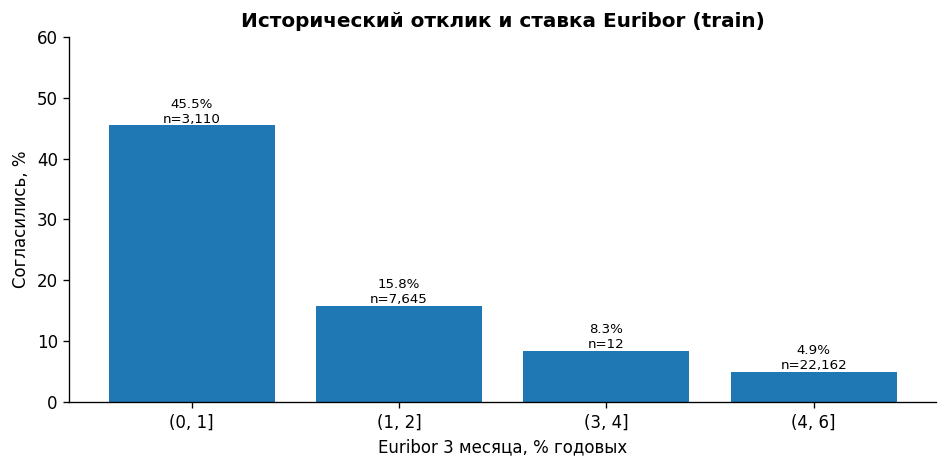

In [6]:
eda['campaign_band'] = pd.cut(
    eda['campaign'],
    bins=[0, 1, 2, 3, 5, 10, 100],
    labels=['1', '2', '3', '4-5', '6-10', '11+'],
)
eda['euribor_band'] = pd.cut(eda['euribor3m'], bins=[0, 1, 2, 3, 4, 6])

numeric_groups = [
    ('campaign_band', 'campaign', 'Число контактов', 'число контактов'),
    ('euribor_band', 'euribor3m', 'Euribor 3 месяца, % годовых', 'ставка Euribor'),
]
for group_column, feature, xlabel, title in numeric_groups:
    table = response_by_group(eda, group_column)
    table.index = table.index.astype(str)
    eda_tables[feature] = table
    plot_response(
        table,
        f'Исторический отклик и {title} (train)',
        xlabel=xlabel,
    )

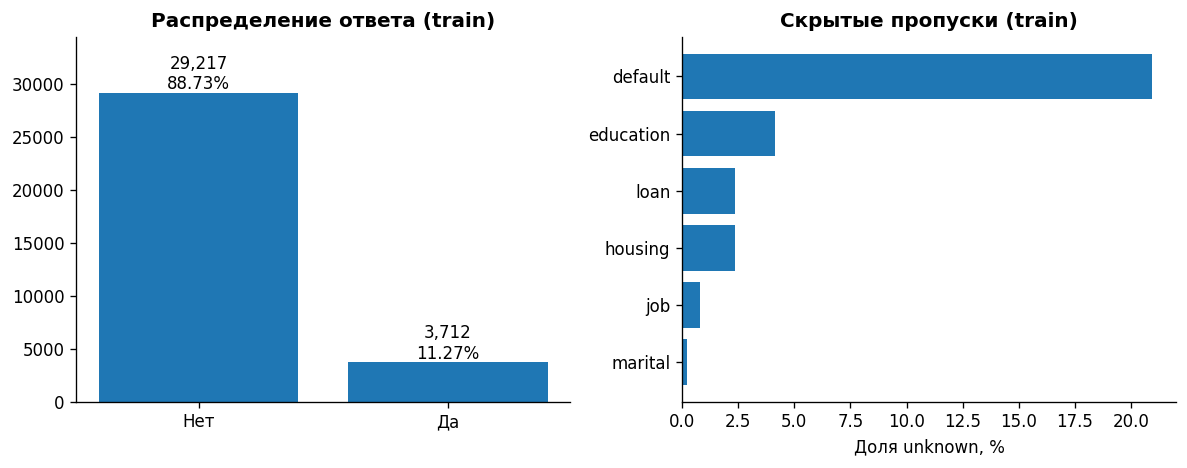

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
class_counts = eda['target'].value_counts().reindex([0, 1])
axes[0].bar(['Нет', 'Да'], class_counts)
for position, count in enumerate(class_counts):
    axes[0].text(position, count + 300, f'{count:,}\n{count / len(eda):.2%}', ha='center')
axes[0].set(title='Распределение ответа (train)', ylim=(0, class_counts.max() * 1.18))

train_unknown = eda.eq('unknown').sum()
train_unknown = train_unknown[train_unknown > 0].sort_values()
axes[1].barh(train_unknown.index, train_unknown / len(eda) * 100)
axes[1].set(xlabel='Доля unknown, %', title='Скрытые пропуски (train)')
plt.tight_layout()
plt.show()

In [8]:
eda_findings = []
for feature, table in eda_tables.items():
    highest_group = table['response_rate'].idxmax()
    lowest_group = table['response_rate'].idxmin()
    eda_findings.append({
        'feature': feature,
        'highest_group': str(highest_group),
        'highest_rate': table.loc[highest_group, 'response_rate'],
        'highest_n': table.loc[highest_group, 'n'],
        'lowest_group': str(lowest_group),
        'lowest_rate': table.loc[lowest_group, 'response_rate'],
        'lowest_n': table.loc[lowest_group, 'n'],
    })

eda_findings = pd.DataFrame(eda_findings)
display(eda_findings)

correlation, p_value = spearmanr(eda['euribor3m'], eda['target'])
display(pd.Series({
    'Корреляция Спирмена euribor3m и отклика': correlation,
    'Описательное p-value': p_value,
}).to_frame('Значение'))

,feature,highest_group,highest_rate,highest_n,lowest_group,lowest_rate,lowest_n
0,job,student,0.310296,709,blue-collar,0.068666,7369
1,contact,cellular,0.146984,20839,telephone,0.053681,12090
2,month,mar,0.500000,438,may,0.063983,11003
3,poutcome,success,0.646679,1084,nonexistent,0.089366,28456
4,campaign,1,0.130693,14163,11+,0.028129,711
5,euribor3m,"(0, 1]",0.454662,3110,"(4, 6]",0.049274,22162


,Значение
Корреляция Спирмена euribor3m и отклика,-0.26409
Описательное p-value,0.00000


## 2. Подготовка данных

In [9]:
categorical_columns = X_train.select_dtypes(include='object').columns.tolist()
numeric_columns = [column for column in X_train if column not in categorical_columns]
unknown_columns = ['job', 'marital', 'education', 'default', 'housing', 'loan']
engineered_numeric_columns = numeric_columns + ['had_previous_contact', 'unknown_count']


def engineer_features(frame):
    result = frame.copy()
    result['had_previous_contact'] = result['pdays'].ne(999).astype(int)
    result['unknown_count'] = result[unknown_columns].eq('unknown').sum(axis=1)
    result['pdays'] = result['pdays'].replace(999, np.nan)
    return result


def build_pipeline(classifier, scale_numeric=False):
    numeric_steps = [('imputer', SimpleImputer(strategy='median', add_indicator=True))]
    if scale_numeric:
        numeric_steps.append(('scaler', StandardScaler()))

    preprocessing = ColumnTransformer([
        ('num', Pipeline(numeric_steps), engineered_numeric_columns),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_columns),
    ])
    return Pipeline([
        ('features', FunctionTransformer(engineer_features, validate=False)),
        ('preprocess', preprocessing),
        ('model', classifier),
    ])

In [10]:
def top_indices(probabilities, fraction=0.2):
    probabilities = np.asarray(probabilities)
    # Равные вероятности упорядочиваются случайно, без использования правильных ответов.
    tie_breaker = np.random.default_rng(RANDOM_STATE).random(len(probabilities))
    ranking = np.lexsort((tie_breaker, -probabilities))
    limit = max(1, int(np.floor(fraction * len(probabilities))))
    return ranking[:limit]


def recall_at_20(y_true, probabilities):
    labels = np.asarray(y_true)
    return labels[top_indices(probabilities)].sum() / labels.sum()


scoring = {
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision',
    'recall20': make_scorer(recall_at_20, response_method='predict_proba'),
}
cv_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE + 1,
)
cv_splits = list(cv_splitter.split(X_train, y_train, train_groups))

## 3. Обучение и оценка моделей

In [11]:
search_options = {
    'scoring': scoring,
    'refit': 'recall20',
    'cv': cv_splits,
    'n_jobs': 2,
    'return_train_score': True,
}

searches = {
    'Logistic Regression': GridSearchCV(
        build_pipeline(
            LogisticRegression(solver='liblinear', max_iter=1800, random_state=RANDOM_STATE, n_jobs=1),
            scale_numeric=True,
        ),
        param_grid={
            'model__C': [0.01, 0.1, 1.0, 10.0],
            'model__class_weight': [None, 'balanced'],
        },
        **search_options,
    ),
    'Decision Tree': GridSearchCV(
        build_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
        param_grid={
            'model__max_depth': [3, 5, 8, 12],
            'model__min_samples_leaf': [20, 100],
            'model__class_weight': [None, 'balanced'],
        },
        **search_options,
    ),
    'Random Forest': RandomizedSearchCV(
        build_pipeline(RandomForestClassifier(
            n_estimators=180,
            random_state=RANDOM_STATE,
            n_jobs=1,
        )),
        param_distributions={
            'model__max_depth': [6, 10, 16, None],
            'model__min_samples_leaf': [5, 20, 60],
            'model__max_features': ['sqrt', 0.6],
            'model__class_weight': [None, 'balanced_subsample'],
        },
        n_iter=10,
        random_state=RANDOM_STATE,
        **search_options,
    ),
}

In [12]:
cv_rows = []
for model_name, search in searches.items():
    with parallel_backend('threading', n_jobs=2):
        search.fit(X_train, y_train)

    cv_results = pd.DataFrame(search.cv_results_)
    best_index = search.best_index_
    cv_rows.append({
        'model': model_name,
        'cv_recall20': cv_results.loc[best_index, 'mean_test_recall20'],
        'cv_recall20_sd': cv_results.loc[best_index, 'std_test_recall20'],
        'cv_roc_auc': cv_results.loc[best_index, 'mean_test_roc_auc'],
        'cv_pr_auc': cv_results.loc[best_index, 'mean_test_pr_auc'],
        'best_params': search.best_params_,
    })

cv_comparison = pd.DataFrame(cv_rows).sort_values('cv_recall20', ascending=False)
selected_name = cv_comparison.iloc[0]['model']
selected_model = searches[selected_name].best_estimator_
display(cv_comparison)

,model,cv_recall20,cv_recall20_sd,cv_roc_auc,cv_pr_auc,best_params
2,Random Forest,0.638697,0.010343,0.794106,0.466382,"{'model__min_samples_leaf': 20, 'model__max_fe..."
1,Decision Tree,0.629423,0.007004,0.783640,0.444364,"{'model__class_weight': None, 'model__max_dept..."
0,Logistic Regression,0.624409,0.012555,0.784631,0.448608,"{'model__C': 1.0, 'model__class_weight': None}"


In [13]:
with parallel_backend('threading', n_jobs=2):
    oof_probabilities = cross_val_predict(
        clone(selected_model),
        X_train,
        y_train,
        cv=cv_splits,
        method='predict_proba',
        n_jobs=2,
    )[:, 1]

threshold_rows = []
for candidate_threshold in np.r_[np.linspace(0, 1, 201), np.inf]:
    contact_mask = oof_probabilities >= candidate_threshold
    contacts = contact_mask.sum()
    successes = y_train.to_numpy()[contact_mask].sum()
    threshold_rows.append({
        'threshold': candidate_threshold,
        'contacts': contacts,
        'successes': successes,
        'profit': successes * DEPOSIT_MARGIN - contacts * CALL_COST,
    })

threshold_table = pd.DataFrame(threshold_rows)
best_threshold = threshold_table.sort_values(
    ['profit', 'contacts'],
    ascending=[False, True],
).iloc[0]
threshold = best_threshold['threshold']

display(best_threshold.to_frame('Выбранный порог'))

,Выбранный порог
threshold,0.13
contacts,5865.00
successes,2309.00
profit,86125.00


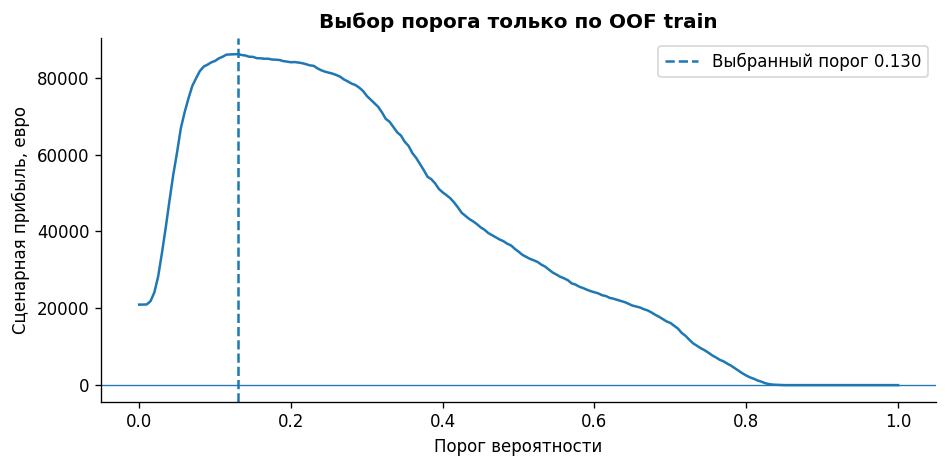

In [14]:
finite_thresholds = threshold_table[np.isfinite(threshold_table['threshold'])]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(finite_thresholds['threshold'], finite_thresholds['profit'])
ax.axvline(threshold, linestyle='--', label=f'Выбранный порог {threshold:.3f}')
ax.axhline(0, linewidth=0.8)
ax.set(
    xlabel='Порог вероятности',
    ylabel='Сценарная прибыль, евро',
    title='Выбор порога только по OOF train',
)
ax.legend()
plt.tight_layout()
plt.show()

In [15]:
def calculate_metrics(model_name, labels, probabilities, threshold=0.5, split='test'):
    predictions = probabilities >= threshold
    return {
        'model': model_name,
        'split': split,
        'threshold': threshold,
        'n': len(labels),
        'precision': precision_score(labels, predictions, zero_division=0),
        'recall': recall_score(labels, predictions, zero_division=0),
        'f1': f1_score(labels, predictions, zero_division=0),
        'roc_auc': roc_auc_score(labels, probabilities),
        'pr_auc': average_precision_score(labels, probabilities),
        'recall20': recall_at_20(labels, probabilities),
        'accuracy': accuracy_score(labels, predictions),
        'brier': brier_score_loss(labels, probabilities),
    }


metric_rows = []
test_probabilities = {}
for model_name, search in searches.items():
    model = search.best_estimator_
    train_probability = model.predict_proba(X_train)[:, 1]
    test_probability = model.predict_proba(X_test)[:, 1]
    test_probabilities[model_name] = test_probability
    metric_rows.append(calculate_metrics(model_name, y_test, test_probability))
    metric_rows.append(calculate_metrics(model_name, y_train, train_probability, split='train'))

baseline = DummyClassifier(strategy='prior', random_state=RANDOM_STATE)
baseline.fit(X_train, y_train)
baseline_probability = baseline.predict_proba(X_test)[:, 1]
metric_rows.append(calculate_metrics('Baseline prior', y_test, baseline_probability))
metrics = pd.DataFrame(metric_rows)
display(metrics[metrics['split'].eq('test')].round(4))

,model,split,threshold,n,precision,recall,f1,roc_auc,pr_auc,recall20,accuracy,brier
0,Logistic Regression,test,0.5,8259,0.6730,0.2306,0.3435,0.8077,0.4573,0.6347,0.9010,0.0773
2,Decision Tree,test,0.5,8259,0.6467,0.2209,0.3293,0.8022,0.4448,0.6476,0.8989,0.0776
4,Random Forest,test,0.5,8259,0.6738,0.2381,0.3519,0.8069,0.4778,0.6552,0.9014,0.0755
6,Baseline prior,test,0.5,8259,0.0000,0.0000,0.0000,0.5000,0.1124,0.1983,0.8876,0.0997


In [16]:
selected_probability = test_probabilities[selected_name]
test_labels = y_test.to_numpy()
tuned_metrics = calculate_metrics(selected_name, test_labels, selected_probability, threshold)

display(pd.Series(tuned_metrics).to_frame('Экономический порог'))

confusion_rows = []
for model_name, probabilities in test_probabilities.items():
    tn, fp, fn, tp = confusion_matrix(
        test_labels,
        probabilities >= 0.5,
        labels=[0, 1],
    ).ravel()
    confusion_rows.append({'model': model_name, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp})
confusion_all_models = pd.DataFrame(confusion_rows)
display(confusion_all_models)

,Экономический порог
model,Random Forest
split,test
threshold,0.13
n,8259
precision,0.401505
recall,0.632543
f1,0.491213
roc_auc,0.806887
pr_auc,0.47779
recall20,0.655172


,model,TN,FP,FN,TP
0,Logistic Regression,7227,104,714,214
1,Decision Tree,7219,112,723,205
2,Random Forest,7224,107,707,221


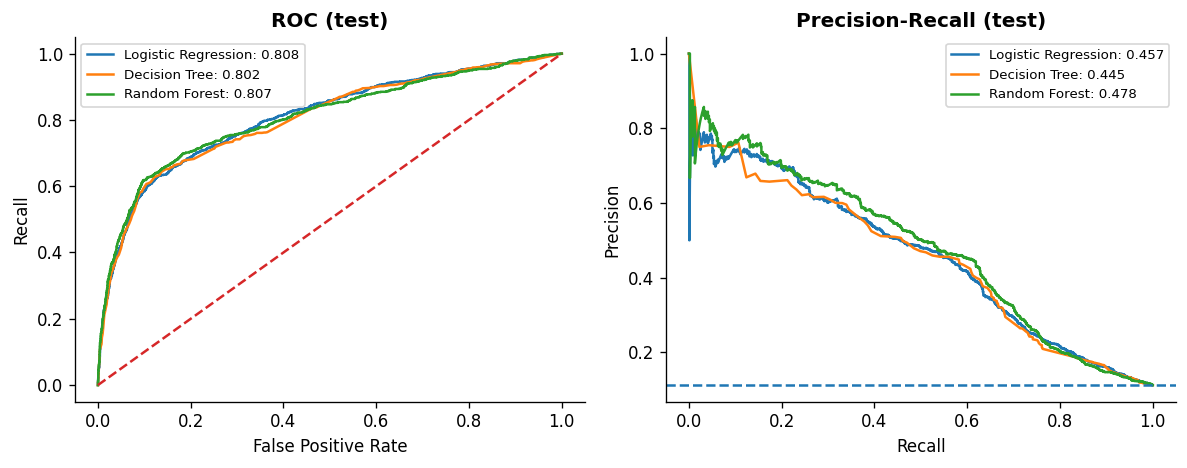

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for model_name, probabilities in test_probabilities.items():
    false_positive_rate, true_positive_rate, _ = roc_curve(test_labels, probabilities)
    precision, recall, _ = precision_recall_curve(test_labels, probabilities)
    roc_auc = roc_auc_score(test_labels, probabilities)
    average_precision = average_precision_score(test_labels, probabilities)
    axes[0].plot(false_positive_rate, true_positive_rate, label=f'{model_name}: {roc_auc:.3f}')
    axes[1].plot(recall, precision, label=f'{model_name}: {average_precision:.3f}')

axes[0].plot([0, 1], [0, 1], linestyle='--')
axes[0].set(xlabel='False Positive Rate', ylabel='Recall', title='ROC (test)')
axes[1].axhline(test_labels.mean(), linestyle='--')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision-Recall (test)')
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

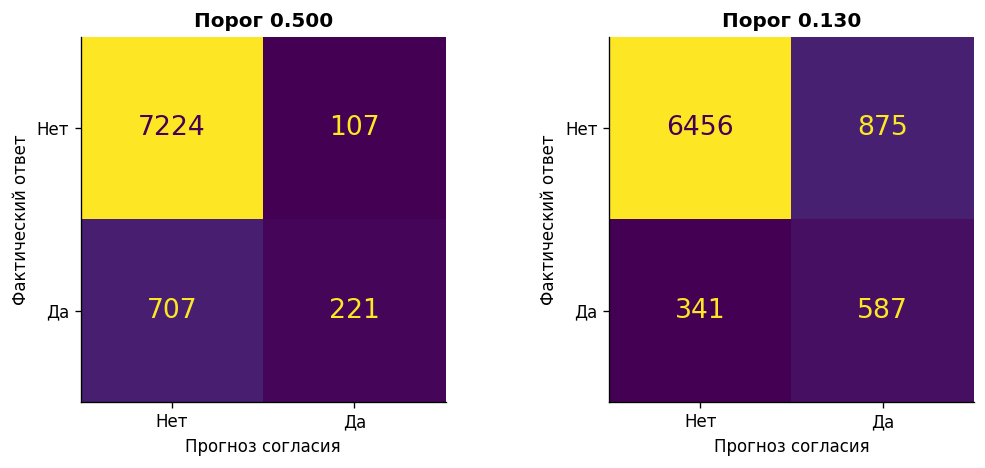

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, probability_threshold in zip(axes, [0.5, threshold]):
    matrix = confusion_matrix(
        test_labels,
        selected_probability >= probability_threshold,
        labels=[0, 1],
    )
    ConfusionMatrixDisplay(matrix, display_labels=['Нет', 'Да']).plot(
        ax=ax,
        colorbar=False,
        text_kw={'fontsize': 16},
    )
    ax.set(
        xlabel='Прогноз согласия',
        ylabel='Фактический ответ',
        title=f'Порог {probability_threshold:.3f}',
    )
plt.tight_layout()
plt.show()

## 4. Охват и бизнес-эффект

In [19]:
client_count = len(test_labels)
positive_count = test_labels.sum()
contact_limit = int(np.floor(0.2 * client_count))
top_clients = top_indices(selected_probability)

top_mask = np.zeros(client_count, dtype=bool)
top_mask[top_clients] = True
threshold_mask = selected_probability >= threshold
capped_threshold_mask = top_mask & threshold_mask

scenario_masks = {
    'Всем': np.ones(client_count, dtype=bool),
    'Top 20% модели': top_mask,
    'Экономический порог': threshold_mask,
    'Порог и лимит 20%': capped_threshold_mask,
}
scenario_rows = []
for scenario_name, contact_mask in scenario_masks.items():
    contacts = contact_mask.sum()
    successes = test_labels[contact_mask].sum()
    scenario_rows.append({
        'scenario': scenario_name,
        'contacts': contacts,
        'successes': successes,
        'recall': successes / positive_count,
        'precision': successes / contacts if contacts else 0,
        'revenue_eur': successes * DEPOSIT_MARGIN,
        'cost_eur': contacts * CALL_COST,
        'profit_eur': successes * DEPOSIT_MARGIN - contacts * CALL_COST,
    })

random_successes = contact_limit * positive_count / client_count
scenario_rows.insert(1, {
    'scenario': 'Случайные 20% (ожидание)',
    'contacts': contact_limit,
    'successes': random_successes,
    'recall': contact_limit / client_count,
    'precision': positive_count / client_count,
    'revenue_eur': random_successes * DEPOSIT_MARGIN,
    'cost_eur': contact_limit * CALL_COST,
    'profit_eur': random_successes * DEPOSIT_MARGIN - contact_limit * CALL_COST,
})
scenarios = pd.DataFrame(scenario_rows)
display(scenarios.round(3))

,scenario,contacts,successes,recall,precision,revenue_eur,cost_eur,profit_eur
0,Всем,8259,928.00,1.000,0.112,46400.000,41295.0,5105.000
1,Случайные 20% (ожидание),1651,185.51,0.200,0.112,9275.506,8255.0,1020.506
2,Top 20% модели,1651,608.00,0.655,0.368,30400.000,8255.0,22145.000
3,Экономический порог,1462,587.00,0.633,0.402,29350.000,7310.0,22040.000
4,Порог и лимит 20%,1462,587.00,0.633,0.402,29350.000,7310.0,22040.000


In [20]:
rng = np.random.default_rng(RANDOM_STATE)
unique_groups, group_numbers = np.unique(test_groups, return_inverse=True)
group_positions = [
    np.flatnonzero(group_numbers == group_number)
    for group_number in range(len(unique_groups))
]
bootstrap_recalls = []
for _ in range(700):
    sampled_groups = rng.integers(0, len(group_positions), size=len(group_positions))
    sampled_indices = np.concatenate([group_positions[number] for number in sampled_groups])
    sampled_labels = test_labels[sampled_indices]
    if sampled_labels.sum():
        bootstrap_recalls.append(recall_at_20(
            sampled_labels,
            selected_probability[sampled_indices],
        ))

recall_interval = np.quantile(bootstrap_recalls, [0.025, 0.975])
random_success_interval = hypergeom.ppf(
    [0.025, 0.975],
    client_count,
    positive_count,
    contact_limit,
)
coverage_summary = pd.Series({
    'Размер test': client_count,
    'Все согласия test': positive_count,
    'Лимит контактов': contact_limit,
    'Согласия в top 20%': test_labels[top_clients].sum(),
    'Recall@20%': test_labels[top_clients].sum() / positive_count,
    'Нижняя граница 95% интервала Recall@20%': recall_interval[0],
    'Верхняя граница 95% интервала Recall@20%': recall_interval[1],
    'Ожидаемые согласия при случайном отборе': random_successes,
    'Нижняя граница 95% диапазона случайных согласий': random_success_interval[0],
    'Верхняя граница 95% диапазона случайных согласий': random_success_interval[1],
    'Lift@20%': (test_labels[top_clients].sum() / positive_count) / (contact_limit / client_count),
}, name='Значение')
display(coverage_summary.to_frame())

,Значение
Размер test,8259.000000
Все согласия test,928.000000
Лимит контактов,1651.000000
Согласия в top 20%,608.000000
Recall@20%,0.655172
Нижняя граница 95% интервала Recall@20%,0.626562
Верхняя граница 95% интервала Recall@20%,0.684424
Ожидаемые согласия при случайном отборе,185.510110
Нижняя граница 95% диапазона случайных согласий,163.000000
Верхняя граница 95% диапазона случайных согласий,208.000000


In [21]:
sensitivity_rows = []
for call_cost in [2, 5, 10]:
    for deposit_margin in [25, 50, 100]:
        all_profit = positive_count * deposit_margin - client_count * call_cost
        top_profit = test_labels[top_clients].sum() * deposit_margin - contact_limit * call_cost
        sensitivity_rows.append({
            'call_cost_eur': call_cost,
            'margin_eur': deposit_margin,
            'all_profit': all_profit,
            'top20_profit': top_profit,
            'top20_minus_all': top_profit - all_profit,
        })

sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity)

,call_cost_eur,margin_eur,all_profit,top20_profit,top20_minus_all
0,2,25,6682,11898,5216
1,2,50,29882,27098,-2784
2,2,100,76282,57498,-18784
3,5,25,-18095,6945,25040
4,5,50,5105,22145,17040
5,5,100,51505,52545,1040
6,10,25,-59390,-1310,58080
7,10,50,-36190,13890,50080
8,10,100,10210,44290,34080


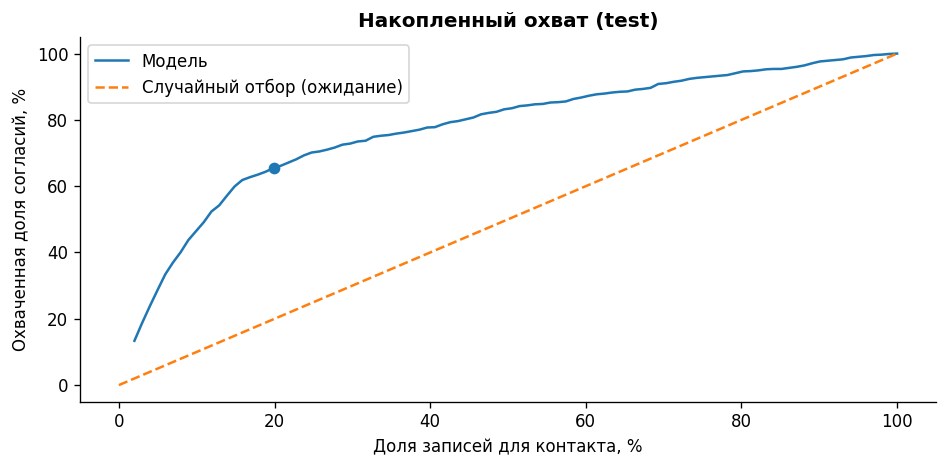

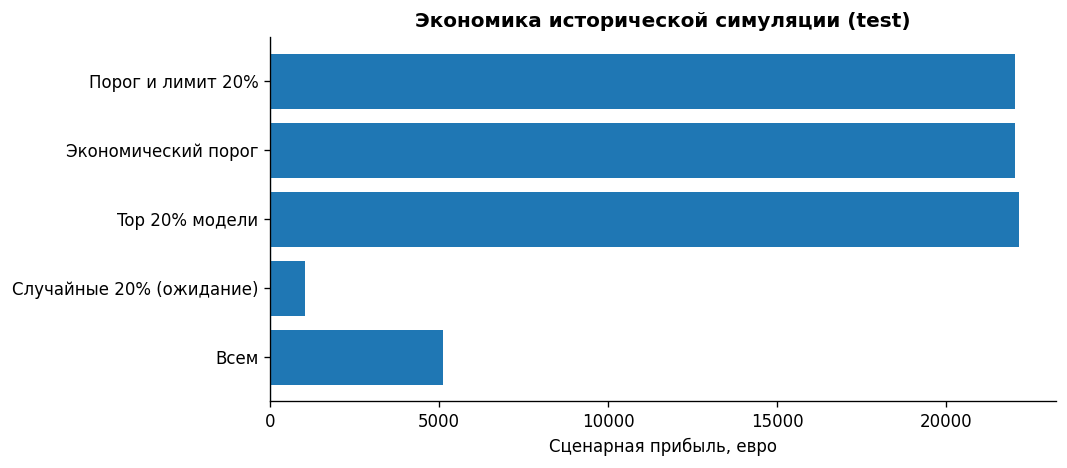

In [22]:
fractions = np.linspace(0.02, 1, 100)
coverage = [
    test_labels[top_indices(selected_probability, fraction)].sum() / positive_count
    for fraction in fractions
]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(fractions * 100, np.asarray(coverage) * 100, label='Модель')
ax.plot([0, 100], [0, 100], linestyle='--', label='Случайный отбор (ожидание)')
ax.scatter(
    [100 * contact_limit / client_count],
    [100 * test_labels[top_clients].sum() / positive_count],
    zorder=3,
)
ax.set(
    xlabel='Доля записей для контакта, %',
    ylabel='Охваченная доля согласий, %',
    title='Накопленный охват (test)',
)
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(scenarios['scenario'], scenarios['profit_eur'])
ax.axvline(0, linewidth=0.7)
ax.set(xlabel='Сценарная прибыль, евро', title='Экономика исторической симуляции (test)')
plt.tight_layout()
plt.show()

## 5. Интерпретация модели

,feature,importance,repeat_sd
7,contact,0.025237,0.001566
13,emp.var.rate,0.018432,0.004324
17,nr.employed,0.011385,0.002388
16,euribor3m,0.010275,0.002408
8,month,0.009204,0.003692
14,cons.price.idx,0.008726,0.002200
10,pdays,0.007375,0.001277
15,cons.conf.idx,0.006509,0.001139
12,poutcome,0.005301,0.001149
9,day_of_week,0.003461,0.002138


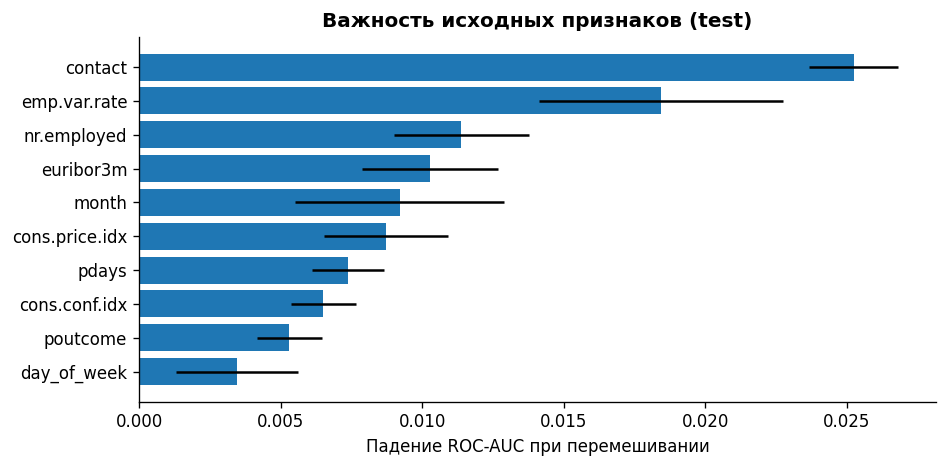

In [23]:
with parallel_backend('threading', n_jobs=2):
    permutation = permutation_importance(
        selected_model,
        X_test,
        y_test,
        scoring='roc_auc',
        n_repeats=5,
        random_state=RANDOM_STATE,
        n_jobs=2,
    )

importance = pd.DataFrame({
    'feature': X_test.columns,
    'importance': permutation.importances_mean,
    'repeat_sd': permutation.importances_std,
}).sort_values('importance', ascending=False)
display(importance.head(10))

plotted_importance = importance.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(
    plotted_importance['feature'],
    plotted_importance['importance'],
    xerr=plotted_importance['repeat_sd'],
)
ax.set(
    xlabel='Падение ROC-AUC при перемешивании',
    title='Важность исходных признаков (test)',
)
plt.tight_layout()
plt.show()

In [24]:
train_probability = selected_model.predict_proba(X_train)[:, 1]
factor_directions = []
factor_profiles = {}

for feature in importance.head(5)['feature']:
    values = X_train[feature]
    if pd.api.types.is_numeric_dtype(values) and values.nunique() > 6:
        profile_groups = pd.qcut(values, q=4, duplicates='drop').astype(str)
    else:
        profile_groups = values.astype(str)

    profile_data = pd.DataFrame({
        'group': profile_groups.to_numpy(),
        'prob': train_probability,
        'y': y_train.to_numpy(),
    })
    profile = profile_data.groupby('group', sort=False).agg(
        n=('y', 'size'),
        observed=('y', 'mean'),
        predicted=('prob', 'mean'),
    )
    profile = profile[profile['n'] >= 50]
    if values.dtype == 'object':
        profile = profile.sort_values('predicted')

    factor_profiles[feature] = profile
    lowest_group = profile['predicted'].idxmin()
    highest_group = profile['predicted'].idxmax()
    factor_directions.append({
        'feature': feature,
        'low_group': str(lowest_group),
        'low_prediction': profile.loc[lowest_group, 'predicted'],
        'low_observed': profile.loc[lowest_group, 'observed'],
        'low_n': profile.loc[lowest_group, 'n'],
        'high_group': str(highest_group),
        'high_prediction': profile.loc[highest_group, 'predicted'],
        'high_observed': profile.loc[highest_group, 'observed'],
        'high_n': profile.loc[highest_group, 'n'],
    })

factor_directions = pd.DataFrame(factor_directions)
display(factor_directions)

,feature,low_group,low_prediction,low_observed,low_n,high_group,high_prediction,high_observed,high_n
0,contact,telephone,0.056994,0.053681,12090,cellular,0.145178,0.146984,20839
1,emp.var.rate,"(1.1, 1.4]",0.054143,0.053470,12998,"(-3.401, -1.8]",0.213536,0.213892,9617
2,nr.employed,"(5099.1, 5191.0]",0.032938,0.032346,6245,"(4963.599, 5099.1]",0.242852,0.243515,10755
3,euribor3m,"(4.857, 4.961]",0.050889,0.052933,7519,"(0.633, 1.344]",0.252740,0.251073,8388
4,month,may,0.065274,0.063983,11003,mar,0.477309,0.500000,438


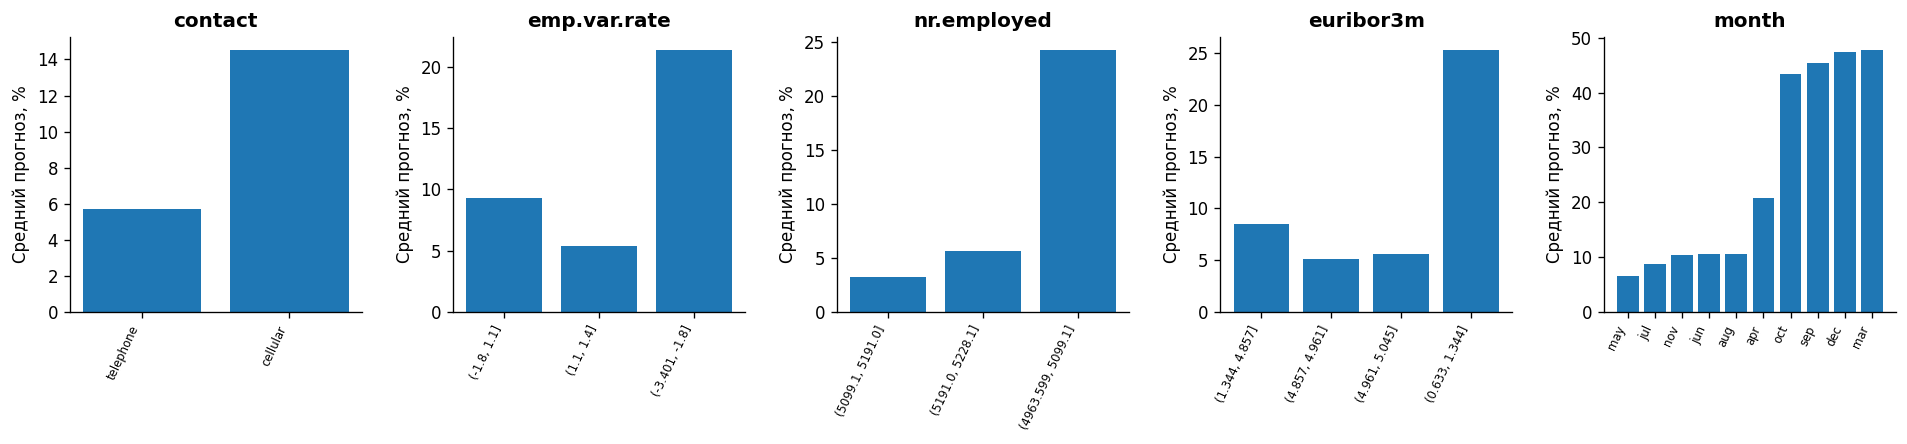

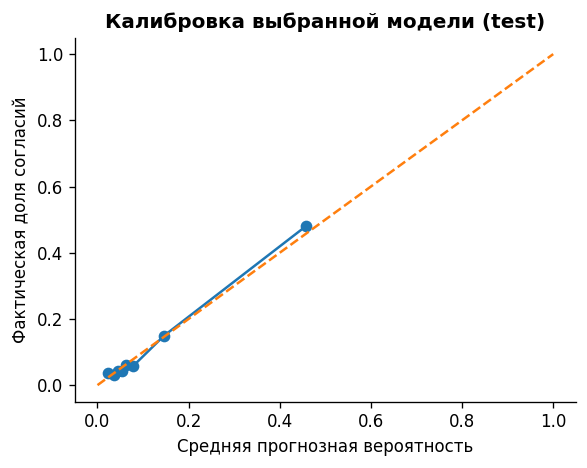

In [25]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.8))
for ax, (feature, profile) in zip(axes, factor_profiles.items()):
    positions = np.arange(len(profile))
    ax.bar(positions, profile['predicted'] * 100)
    ax.set_xticks(positions)
    ax.set_xticklabels(profile.index, rotation=65, ha='right', fontsize=7)
    ax.set(title=feature, ylabel='Средний прогноз, %')
plt.tight_layout()
plt.show()

observed_probability, mean_probability = calibration_curve(
    test_labels,
    selected_probability,
    n_bins=8,
    strategy='quantile',
)
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(mean_probability, observed_probability, 'o-')
ax.plot([0, 1], [0, 1], linestyle='--')
ax.set(
    xlabel='Средняя прогнозная вероятность',
    ylabel='Фактическая доля согласий',
    title='Калибровка выбранной модели (test)',
)
plt.tight_layout()
plt.show()

In [26]:
logistic_model = searches['Logistic Regression'].best_estimator_
coefficients = pd.DataFrame({
    'feature': logistic_model.named_steps['preprocess'].get_feature_names_out(),
    'coefficient': logistic_model.named_steps['model'].coef_[0],
})
largest_coefficients = coefficients['coefficient'].abs().sort_values(ascending=False).head(15).index
display(coefficients.loc[largest_coefficients])

,feature,coefficient
3,num__emp.var.rate,-2.064833
51,cat__month_mar,1.263295
4,num__cons.price.idx,1.063626
50,cat__month_jun,-0.738690
45,cat__contact_telephone,-0.634901
61,cat__poutcome_failure,-0.625595
53,cat__month_nov,-0.607804
52,cat__month_may,-0.603613
57,cat__day_of_week_mon,-0.372659
6,num__euribor3m,0.348489
